<a href="https://colab.research.google.com/github/MohammadIsmail21/-Electricity-Bill-Predictor-/blob/main/electricitybillpredictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv('household_power_consumption.txt', sep=';',low_memory=False, na_values=['?'])
df.to_csv('household_power_consumption.csv', index=False)

print("Conversion complete! Saved as household_power_consumption.csv")

Conversion complete! Saved as household_power_consumption.csv


In [3]:
df = pd.read_csv("/content/household_power_consumption.csv",sep=",",na_values="?")
print(df.head())

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [4]:
df = df[["Date","Global_active_power"]]
print(df.head())

         Date  Global_active_power
0  16/12/2006                4.216
1  16/12/2006                5.360
2  16/12/2006                5.374
3  16/12/2006                5.388
4  16/12/2006                3.666


In [5]:
df["Date"] = pd.to_datetime(df["Date"],dayfirst=True)
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"],errors="coerce")
df = df.dropna()
daily = df.groupby("Date")["Global_active_power"].mean().reset_index()
print(daily.head())

        Date  Global_active_power
0 2006-12-16             3.053475
1 2006-12-17             2.354486
2 2006-12-18             1.530435
3 2006-12-19             1.157079
4 2006-12-20             1.545658


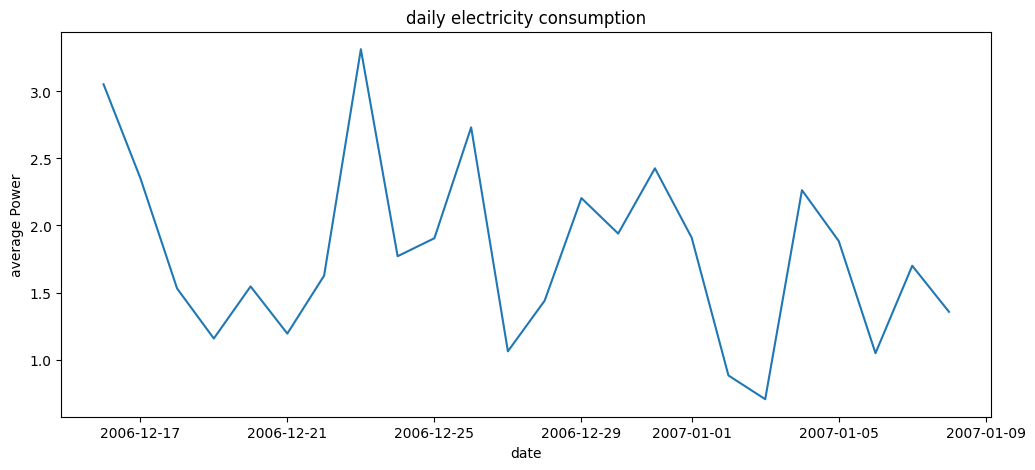

In [6]:
plt.figure(figsize=(12,5))

plt.plot(daily["Date"],daily["Global_active_power"])

plt.xlabel("date")
plt.ylabel("average Power")
plt.title("daily electricity consumption")

plt.show()

In [7]:
daily["Day"] = range(len(daily))

In [8]:
X = daily[["Day"]]
y = daily["Global_active_power"]

model = LinearRegression()

model.fit(X, y)

LinearRegression()

In [9]:
next_day = [[len(daily)]]

prediction = model.predict(next_day)

print("Predicted electricity consumption:",round(prediction[0], 2),"kW")

Predicted electricity consumption: 1.45 kW


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


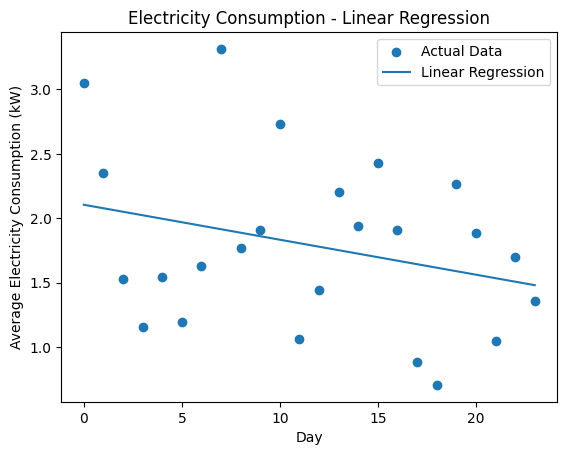

In [10]:
import matplotlib.pyplot as plt
plt.scatter(
    daily["Day"],
    daily["Global_active_power"],
    label="Actual Data")
predicted = model.predict(daily[["Day"]])

plt.plot(
    daily["Day"],
    predicted,
    label="Linear Regression")

plt.xlabel("Day")
plt.ylabel("Average Electricity Consumption (kW)")
plt.title("Electricity Consumption - Linear Regression")

plt.legend()
plt.show()